# Data exploration: BDNeuro-MRI

Dataset: [BDNeuro-MRI v7 (Mendeley Data)](https://data.mendeley.com/datasets/zwr4ntf94j/7), CC BY 4.0.
5,941 T1 contrast-enhanced brain MRI slices, 4 classes (glioma, meningioma, pituitary, no tumor),
pre-split 70/15/15 (train/val/test), stratified per class.

What this notebook checks before any model is trained:

1. **Class distribution** per split, and what it means for loss and metrics
2. **Sample images** per class
3. **Image properties** (resolution, colour mode) per class, i.e. *can the model cheat?*
4. **Intensity statistics**, normalisation constants, mean image per class
5. **Leakage**: near-duplicate images across train/val/test

In [ ]:
import hashlib, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("data")
ZIP_PATH = DATA_DIR / "Brain_Tumor_MRI_Dataset_Final.zip"
ROOT = DATA_DIR / "bdneuro"  # extracted dataset: ROOT/{train,val,test}/{class}/*.jpg
URL = ("https://data.mendeley.com/public-files/datasets/zwr4ntf94j/files/"
       "2d24ea9a-23e3-4a95-898d-06f8cef24c29/file_downloaded")
SHA256 = "0d8fdb6a88b2c65019c11abfd20e0693ffb7b2296955598202303840b9be0c24"

SPLITS = ["train", "val", "test"]
CLASSES = ["glioma", "meningioma", "pituitary", "no_tumor"]
SEED = 1738
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 3)

## 0. Download and extract
Idempotent: skips the ~112 MB download and the extraction if they are already done.

In [2]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()

DATA_DIR.mkdir(exist_ok=True)
if not ZIP_PATH.exists():
    print("Downloading ...")
    urllib.request.urlretrieve(URL, ZIP_PATH)
assert sha256(ZIP_PATH) == SHA256, "checksum mismatch, delete the zip and re-run"

if not (ROOT / "train").exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(ROOT)
print(sorted(p.name for p in ROOT.iterdir()))

['README.md', 'class_distribution.csv', 'class_distribution_final.png', 'model_benchmark.csv', 'model_benchmark.png', 'test', 'train', 'val']


### Build an index and load every image once
One pass over the files: metadata (size, colour mode, file size) plus a 128x128 grayscale copy
that is reused for the intensity, mean-image and duplicate analyses below.

In [3]:
THUMB = 128
rows, thumbs = [], []
for split in SPLITS:
    for cls in CLASSES:
        for p in sorted((ROOT / split / cls).iterdir()):
            with Image.open(p) as im:
                w, h, mode = im.width, im.height, im.mode
                rgb = np.asarray(im.convert("RGB"), dtype=np.int16)
                # is an "RGB" image really just gray stored in 3 channels?
                chroma = int(np.abs(rgb - rgb.mean(axis=2, keepdims=True)).max())
                thumbs.append(np.asarray(im.convert("L").resize((THUMB, THUMB), Image.BILINEAR)))
            rows.append(dict(path=p, split=split, cls=cls, w=w, h=h, mode=mode,
                             kb=p.stat().st_size / 1024, chroma=chroma))

df = pd.DataFrame(rows)
X = np.stack(thumbs)  # (N, 128, 128) uint8
df["cls"] = pd.Categorical(df.cls, CLASSES)
df["split"] = pd.Categorical(df.split, SPLITS)
print(df.shape, X.shape)
df.head()

(5941, 8) (5941, 128, 128)


,path,split,cls,w,h,mode,kb,chroma
0,data/bdneuro/train/glioma/glioma_train_00001.jpg,train,glioma,512,512,L,14.433,0
1,data/bdneuro/train/glioma/glioma_train_00002.jpg,train,glioma,512,512,L,20.386,0
2,data/bdneuro/train/glioma/glioma_train_00003.jpg,train,glioma,512,512,L,18.706,0
3,data/bdneuro/train/glioma/glioma_train_00004.jpg,train,glioma,512,512,L,14.304,0
4,data/bdneuro/train/glioma/glioma_train_00005.jpg,train,glioma,224,224,RGB,7.314,0


## 1. Class distribution

In [4]:
counts = pd.crosstab(df.cls, df.split, margins=True, margins_name="total")
pct = pd.crosstab(df.cls, df.split, normalize="columns").mul(100).round(1)
display(counts)
display(pct.rename(columns=lambda c: f"{c} %"))

split,train,val,test,total
cls,,,,
glioma,1534,329,328,2191
meningioma,1035,222,221,1478
pituitary,1040,223,222,1485
no_tumor,551,118,118,787
total,4160,892,889,5941


split,train %,val %,test %
cls,,,
glioma,36.9,36.9,36.9
meningioma,24.9,24.9,24.9
pituitary,25.0,25.0,25.0
no_tumor,13.2,13.2,13.3


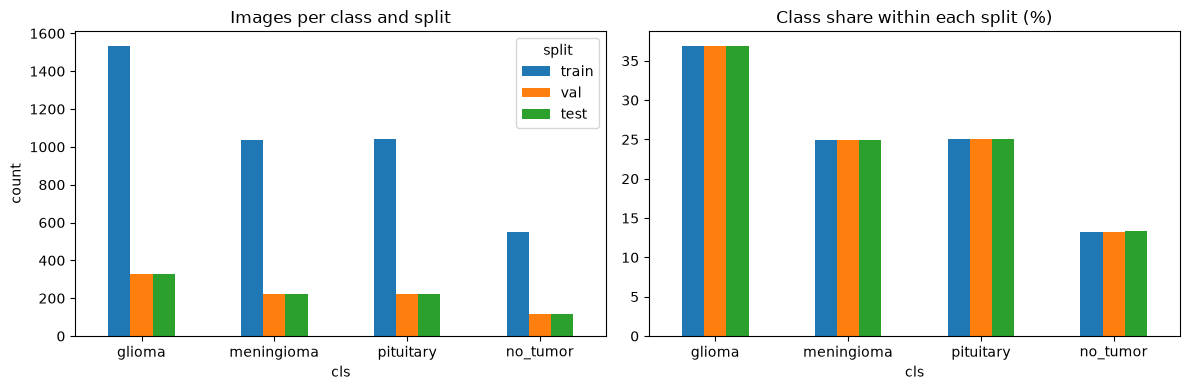

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts.drop(index="total", columns="total").plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Images per class and split"); ax[0].set_ylabel("count")
pct.plot.bar(ax=ax[1], rot=0, legend=False)
ax[1].set_title("Class share within each split (%)")
plt.tight_layout(); plt.show()

In [6]:
train_counts = counts.loc[CLASSES, "train"]
n, k = train_counts.sum(), len(CLASSES)
summary = pd.DataFrame({
    "train_count": train_counts,
    "share": train_counts / n,
    # 'balanced' weights, as in sklearn: n / (k * n_c). Use as nn.CrossEntropyLoss(weight=...)
    "ce_weight": n / (k * train_counts),
})
display(summary)
print(f"Imbalance ratio (largest / smallest class): {train_counts.max() / train_counts.min():.2f}")
print(f"Majority-class baseline accuracy on test:   {(df[df.split=='test'].cls == 'glioma').mean():.3f}")

,train_count,share,ce_weight
cls,,,
glioma,1534,0.369,0.678
meningioma,1035,0.249,1.005
pituitary,1040,0.250,1.000
no_tumor,551,0.132,1.887


Imbalance ratio (largest / smallest class): 2.78
Majority-class baseline accuracy on test:   0.369


**Takeaways**

- Splits are stratified, so class proportions are the same in train/val/test.
- Moderate imbalance (~2.8x): glioma is ~37 %, no tumor only ~13 %. A model that always says
  "glioma" already gets ~37 % accuracy, so plain accuracy is not a good headline metric.
  Report **per-class recall, macro-F1 and balanced accuracy**, plus the confusion matrix.
- Options to counter the imbalance: weighted cross-entropy (weights above), or a
  `WeightedRandomSampler`. Pick one, not both (that double-corrects).
- On the "weighted loss against FN" idea in the plan: in a 4-class softmax setup a false negative
  is specifically *tumor predicted as no_tumor*. Class weights do not target that error; they
  only re-balance class frequencies. If missing a tumor is what you care about, look at the
  `tumor -> no_tumor` cells of the confusion matrix and the binary tumor-vs-no-tumor recall, and
  consider a cost-sensitive loss or a decision threshold on `P(no_tumor)` instead.

## 2. Sample images

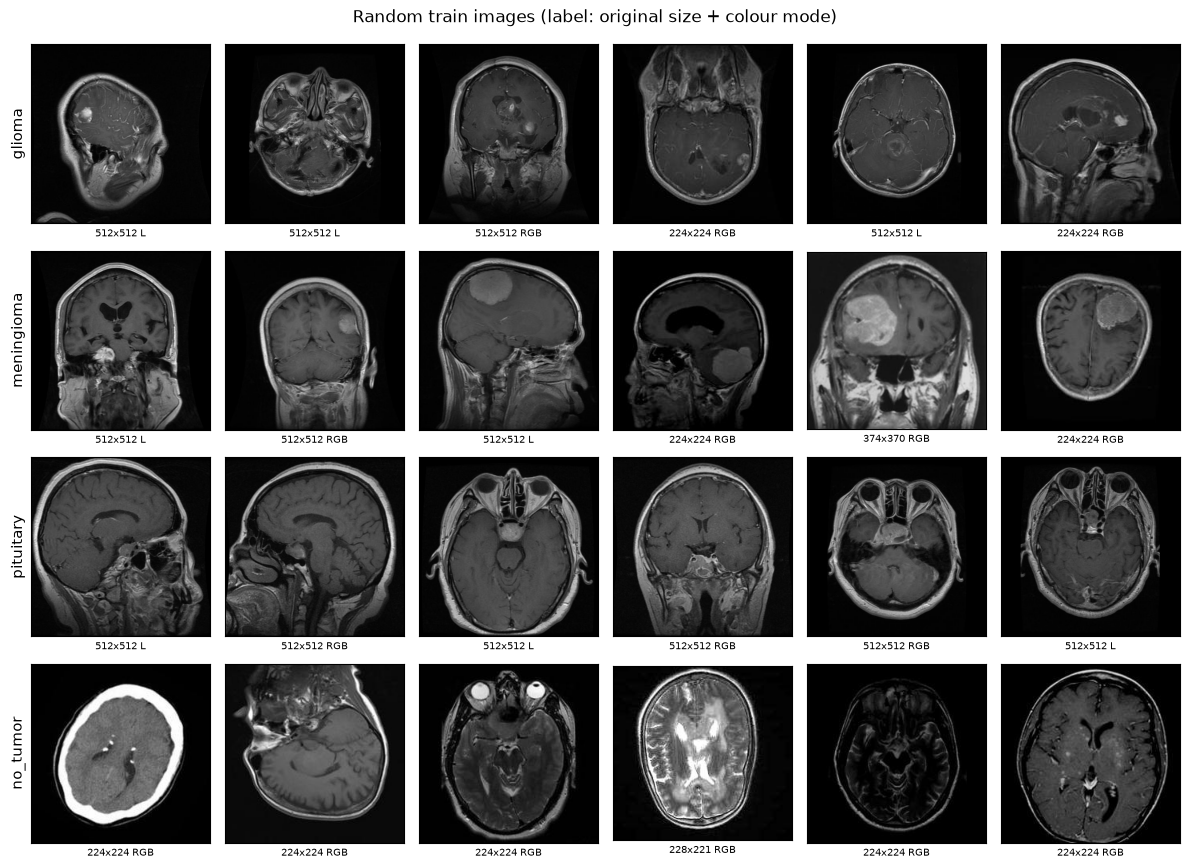

In [7]:
n_per = 6
fig, axes = plt.subplots(len(CLASSES), n_per, figsize=(2 * n_per, 2.2 * len(CLASSES)))
for r, cls in enumerate(CLASSES):
    sub = df[(df.split == "train") & (df.cls == cls)]
    for c, i in enumerate(rng.choice(sub.index, n_per, replace=False)):
        ax = axes[r, c]
        ax.imshow(Image.open(df.path[i]).convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(f"{df.w[i]}x{df.h[i]} {df['mode'][i]}", fontsize=7)
        if c == 0:
            ax.set_ylabel(cls, fontsize=11)
plt.suptitle("Random train images (label: original size + colour mode)")
plt.tight_layout(); plt.show()

The dataset claims to be T1 contrast-enhanced only. Look closely at `no_tumor` below: bright
CSF (T2-weighted), FLAIR-like slices and at least some CT scans show up, which the tumour classes
do not seem to contain. Compare with the tumour rows above.

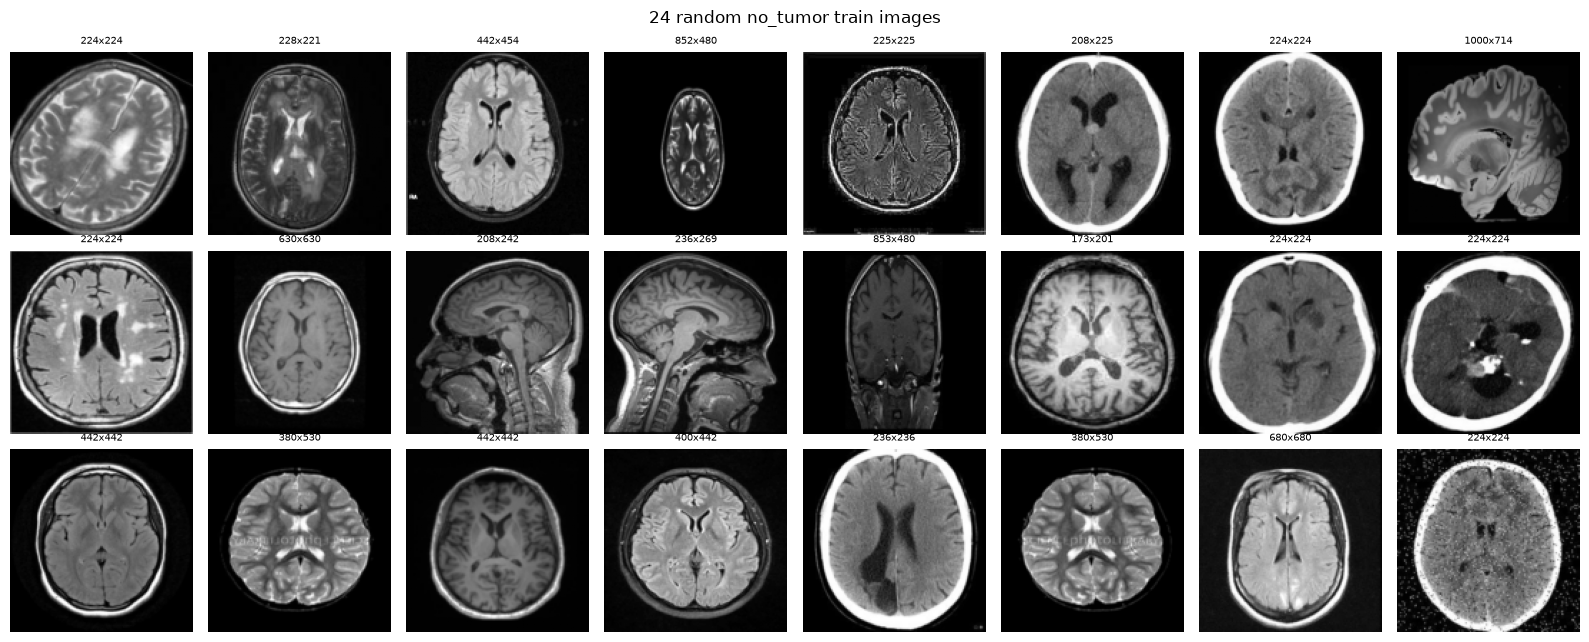

In [8]:
sub = df[(df.split == "train") & (df.cls == "no_tumor")]
idx = rng.choice(sub.index, 24, replace=False)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"{df.w[i]}x{df.h[i]}", fontsize=7)
plt.suptitle("24 random no_tumor train images"); plt.tight_layout(); plt.show()

## 3. Image properties per class: can the model cheat?

The dataset was assembled by pooling images from different sources and re-splitting. If one class
comes mostly from a different source, it will differ in resolution, colour mode, compression,
borders, etc. A CNN will happily learn those artefacts instead of anatomy (*shortcut learning*),
and because the confound is in every split the test score will look great anyway.

In [9]:
def res_bucket(r):
    s = f"{r.w}x{r.h}"
    return s if s in ("512x512", "224x224") else "other"

df["res"] = df.apply(res_bucket, axis=1)
df["square"] = df.w == df.h
df["gray_stored"] = df["mode"].eq("L")
df["truly_gray"] = df.chroma <= 2  # pixels are gray even if stored as RGB

print("Resolution bucket (row %):")
display(pd.crosstab(df.cls, df.res, normalize="index").mul(100).round(1))
print("Stored colour mode (row %):")
display(pd.crosstab(df.cls, df["mode"], normalize="index").mul(100).round(1))
print("Share of images that are actually grayscale pixels / square / file size:")
display(df.groupby("cls", observed=True)[["truly_gray", "square", "kb"]].mean())
print(f"{df[['w', 'h']].drop_duplicates().shape[0]} distinct resolutions in total")

Resolution bucket (row %):


res,224x224,512x512,other
cls,,,
glioma,36.0,62.0,2.0
meningioma,27.7,64.1,8.2
pituitary,32.1,66.4,1.5
no_tumor,36.0,0.5,63.5


Stored colour mode (row %):


mode,L,RGB,RGBA
cls,,,
glioma,41.7,58.3,0.0
meningioma,32.6,67.4,0.0
pituitary,27.0,73.0,0.0
no_tumor,0.5,99.1,0.4


Share of images that are actually grayscale pixels / square / file size:


,truly_gray,square,kb
cls,,,
glioma,1.000,0.984,15.706
meningioma,1.000,0.929,18.337
pituitary,1.000,0.998,23.537
no_tumor,0.959,0.550,19.496


349 distinct resolutions in total


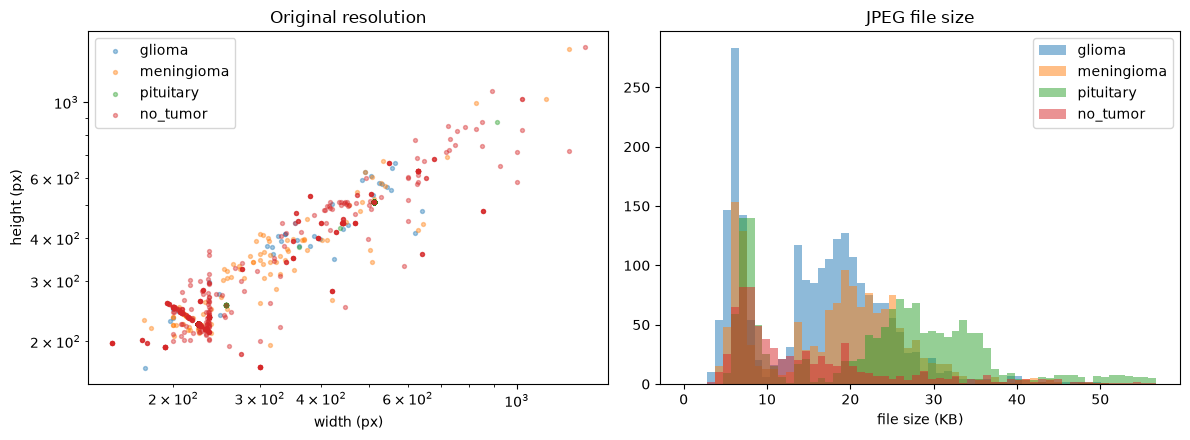

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for cls in CLASSES:
    s = df[df.cls == cls]
    ax[0].scatter(s.w, s.h, s=8, alpha=0.4, label=cls)
    ax[1].hist(s.kb, bins=60, alpha=0.5, label=cls, range=(0, df.kb.quantile(0.99)))
ax[0].set(xscale="log", yscale="log", xlabel="width (px)", ylabel="height (px)", title="Original resolution")
ax[1].set(xlabel="file size (KB)", title="JPEG file size")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

### Metadata-only baseline
How well can a trivial classifier predict the label **without looking at the pixels at all**,
using only width, height, colour mode and file size? Chance (balanced accuracy) is 25 %.
Anything well above that is a measure of how much the CNN could get for free.

Balanced accuracy from metadata only: 0.513
              precision    recall  f1-score   support

      glioma      0.533     0.512     0.523       328
  meningioma      0.350     0.326     0.337       221
    no_tumor      0.561     0.627     0.592       118
   pituitary      0.551     0.586     0.568       222

    accuracy                          0.499       889
   macro avg      0.499     0.513     0.505       889
weighted avg      0.496     0.499     0.497       889



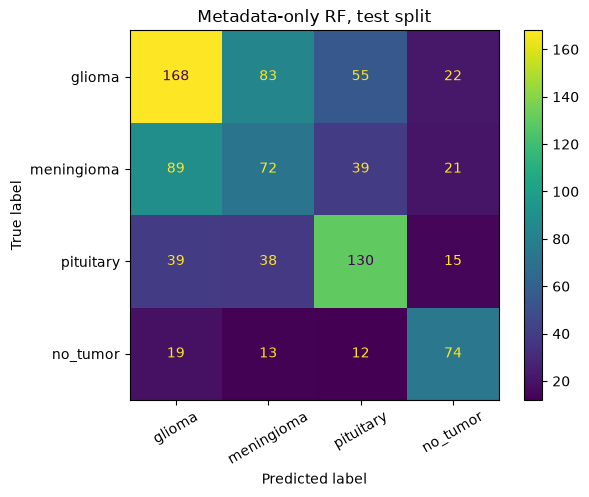

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report, ConfusionMatrixDisplay

meta = pd.DataFrame({
    "w": df.w, "h": df.h, "aspect": df.w / df.h, "kb": df.kb,
    "is_L": df.gray_stored.astype(int), "truly_gray": df.truly_gray.astype(int),
})
tr, te = df.split == "train", df.split == "test"
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED)
rf.fit(meta[tr], df.cls[tr])
pred = rf.predict(meta[te])
print(f"Balanced accuracy from metadata only: {balanced_accuracy_score(df.cls[te], pred):.3f}")
print(classification_report(df.cls[te], pred, digits=3))
ConfusionMatrixDisplay.from_predictions(df.cls[te], pred, labels=CLASSES, xticks_rotation=30)
plt.title("Metadata-only RF, test split"); plt.show()

## 4. Intensity statistics

In [12]:
Xf = X.astype(np.float32) / 255.0
df["mean_px"] = Xf.mean(axis=(1, 2))
df["std_px"] = Xf.std(axis=(1, 2))
df["frac_black"] = (X < 10).mean(axis=(1, 2))  # background / padding share

display(df.groupby("cls", observed=True)[["mean_px", "std_px", "frac_black"]].agg(["mean", "std"]))

# Normalisation constants: train split only (never peek at val/test)
tr_px = Xf[(df.split == "train").to_numpy()]
print(f"Train grayscale mean = {tr_px.mean():.4f}, std = {tr_px.std():.4f}  (at {THUMB}x{THUMB})")

mean_px        std_px        frac_black       
              mean    std   mean    std       mean    std
cls                                                      
glioma       0.141  0.057  0.148  0.033      0.472  0.154
meningioma   0.175  0.064  0.175  0.034      0.436  0.158
pituitary    0.192  0.054  0.153  0.023      0.299  0.137
no_tumor     0.234  0.089  0.213  0.061      0.306  0.209

Train grayscale mean = 0.1749, std = 0.1840  (at 128x128)


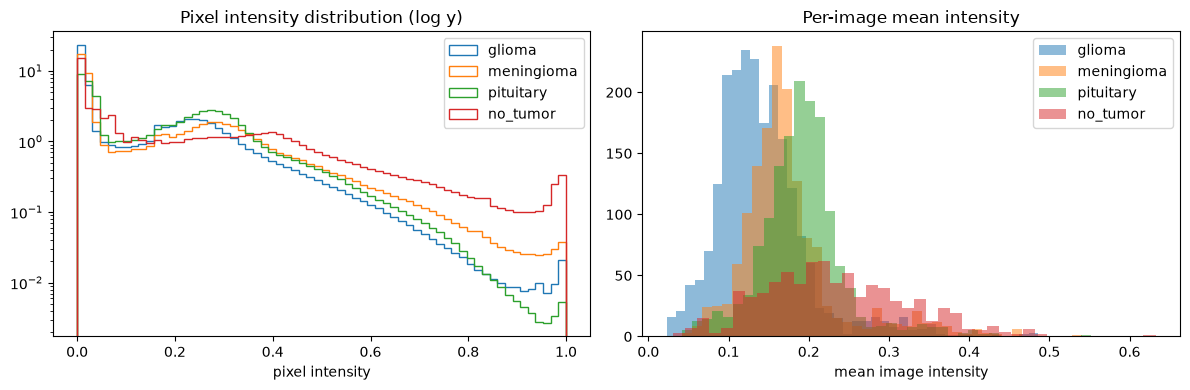

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cls in CLASSES:
    m = (df.cls == cls).to_numpy()
    ax[0].hist(Xf[m].ravel(), bins=64, density=True, histtype="step", label=cls)
    ax[1].hist(df.mean_px[m], bins=40, alpha=0.5, label=cls)
ax[0].set(yscale="log", xlabel="pixel intensity", title="Pixel intensity distribution (log y)")
ax[1].set(xlabel="mean image intensity", title="Per-image mean intensity")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

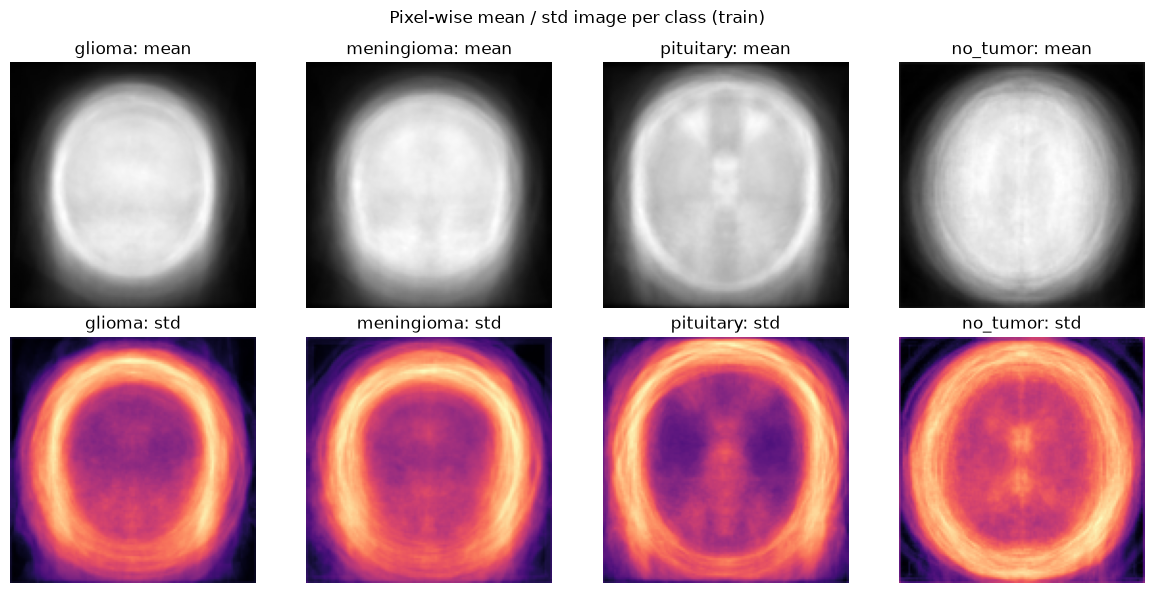

In [14]:
fig, axes = plt.subplots(2, len(CLASSES), figsize=(3 * len(CLASSES), 6))
for c, cls in enumerate(CLASSES):
    m = ((df.cls == cls) & (df.split == "train")).to_numpy()
    axes[0, c].imshow(Xf[m].mean(0), cmap="gray"); axes[0, c].set_title(f"{cls}: mean")
    axes[1, c].imshow(Xf[m].std(0), cmap="magma"); axes[1, c].set_title(f"{cls}: std")
for a in axes.ravel():
    a.axis("off")
plt.suptitle("Pixel-wise mean / std image per class (train)")
plt.tight_layout(); plt.show()

Mean images reveal systematic differences in framing, orientation (axial / coronal / sagittal mix),
zoom and borders. Tumours themselves should mostly average out; anything that stays sharp in a
class mean is a property of how that class was *acquired*, not of the pathology.

## 5. Leakage: near-duplicates across splits

The authors removed duplicates with a perceptual hash (Hamming <= 5) and report zero overlap.
Independent check: for every val/test image, find its most similar image in another split by
Pearson correlation of 32x32 grayscale thumbnails (a 64-bit perceptual hash is useless here:
the large black background makes unrelated MRIs hash alike).

This cannot detect **patient-level** leakage (neighbouring slices of the same patient look
similar but are not duplicates), and the dataset README states the split is image-level only.

In [15]:
def thumb_vecs(size=32):
    v = np.stack([np.asarray(Image.fromarray(x).resize((size, size), Image.BILINEAR), np.float32).ravel()
                  for x in X])
    v -= v.mean(1, keepdims=True)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)

V = thumb_vecs()

def nearest(a, b):
    """For each image in split b, its most correlated image in split a."""
    ia, ib = np.where(df.split == a)[0], np.where(df.split == b)[0]
    C = V[ia] @ V[ib].T
    return pd.DataFrame({"i": ia[C.argmax(0)], "j": ib, "corr": C.max(0)})

nn_pairs = {f"{a}->{b}": nearest(a, b) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
thr = [0.999, 0.99, 0.98, 0.95]
display(pd.DataFrame({k: [(p["corr"] >= t).sum() for t in thr] for k, p in nn_pairs.items()},
                     index=[f"corr >= {t}" for t in thr]))

,train->val,train->test,val->test
corr >= 0.999,1,0,0
corr >= 0.99,13,9,3
corr >= 0.98,60,56,22
corr >= 0.95,344,338,107


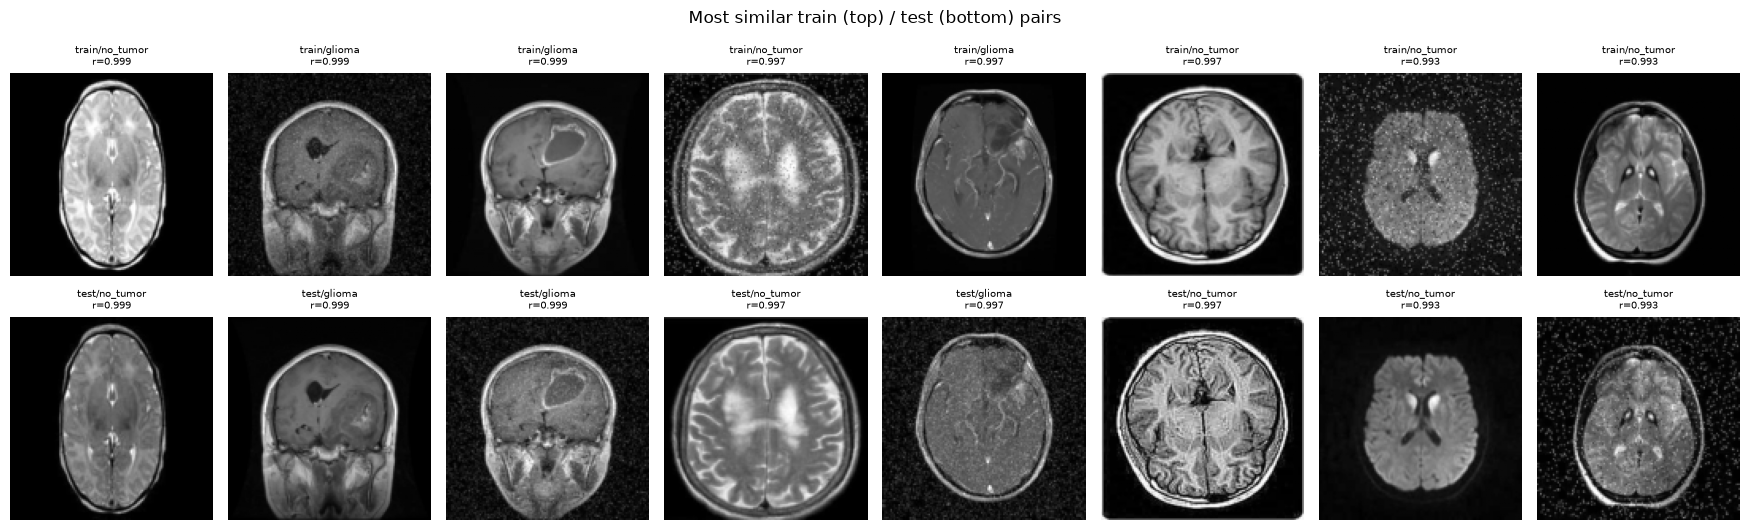

In [16]:
pairs = nn_pairs["train->test"].sort_values("corr", ascending=False).head(8)
fig, axes = plt.subplots(2, len(pairs), figsize=(2.2 * len(pairs), 5.6))
for k, (_, r) in enumerate(pairs.iterrows()):
    for row, idx in enumerate((int(r.i), int(r.j))):
        axes[row, k].imshow(X[idx], cmap="gray"); axes[row, k].axis("off")
        axes[row, k].set_title(f"{df.split[idx]}/{df.cls[idx]}\nr={r['corr']:.3f}", fontsize=7)
plt.suptitle("Most similar train (top) / test (bottom) pairs"); plt.tight_layout(); plt.show()

## 6. Summary and decisions before training

**Class balance.** Stratified splits, ~2.8x imbalance (glioma 37 %, no_tumor 13 %).
Majority baseline is 37 % accuracy. Report per-class recall, macro-F1, balanced accuracy and the
confusion matrix; use weighted CE (weights in section 1) *or* a weighted sampler.

**Shortcut risk (the big one).** The classes come from different sources:
- `no_tumor` is 64 % odd, non-square resolutions and 99 % RGB-stored; the tumour classes are
  ~62-66 % 512x512 and 27-42 % stored as single-channel.
- `no_tumor` mixes MRI sequences (T2, FLAIR, non-contrast T1), CT scans, watermarked stock images and
  at least one rendered illustration, while the tumour classes look like T1 post-contrast. Some CT
  "no tumour" images even show other pathology (e.g. bleeding).
- A random forest on width/height/file size alone reaches ~0.5 balanced accuracy (chance 0.25),
  with ~63 % recall on no_tumor, *without seeing a single pixel*.

So a high test score does not prove the CNN learned pathology, in particular for no_tumor.
Mitigations: convert everything to 1-channel grayscale, resize every image to one fixed size
(e.g. 224x224, pad to square first to avoid aspect-ratio cues), normalise per image, and
use Grad-CAM / saliency on a few predictions in the report to show *where* the model looks.
Mention this limitation explicitly; it is exactly the kind of critical observation graders like.

**Leakage.** Exact and near-identical duplicates were mostly removed, but there remain a few dozen
val/test images with r >= 0.98 to a train image, several of them the same slice with added noise
(augmented copies in the source data). Also, the split is image-level, not patient-level. Options:
drop val/test images above a correlation threshold (e.g. 0.98) to their nearest train image, or at
least report test accuracy with and without them.

**Preprocessing numbers.** Grayscale train mean ~0.175, std ~0.184 (from 128x128 thumbnails;
recompute at the final resolution). Large black background (30-47 % of pixels), so cropping to
the brain bounding box is worth considering.

**Reference point.** Authors' benchmark on this test split: from-scratch CNN 0.847, fine-tuned
DenseNet121 0.983 accuracy. Your deep CNN from scratch should be compared against the 0.847.